In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error, mean_squared_log_error, PredictionErrorDisplay
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
#https://www.kaggle.com/datasets/awaiskaggler/insurance-csv
insurance = pd.read_csv('insurance.csv')

# data exploration and cleaning

In [4]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
insurance.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


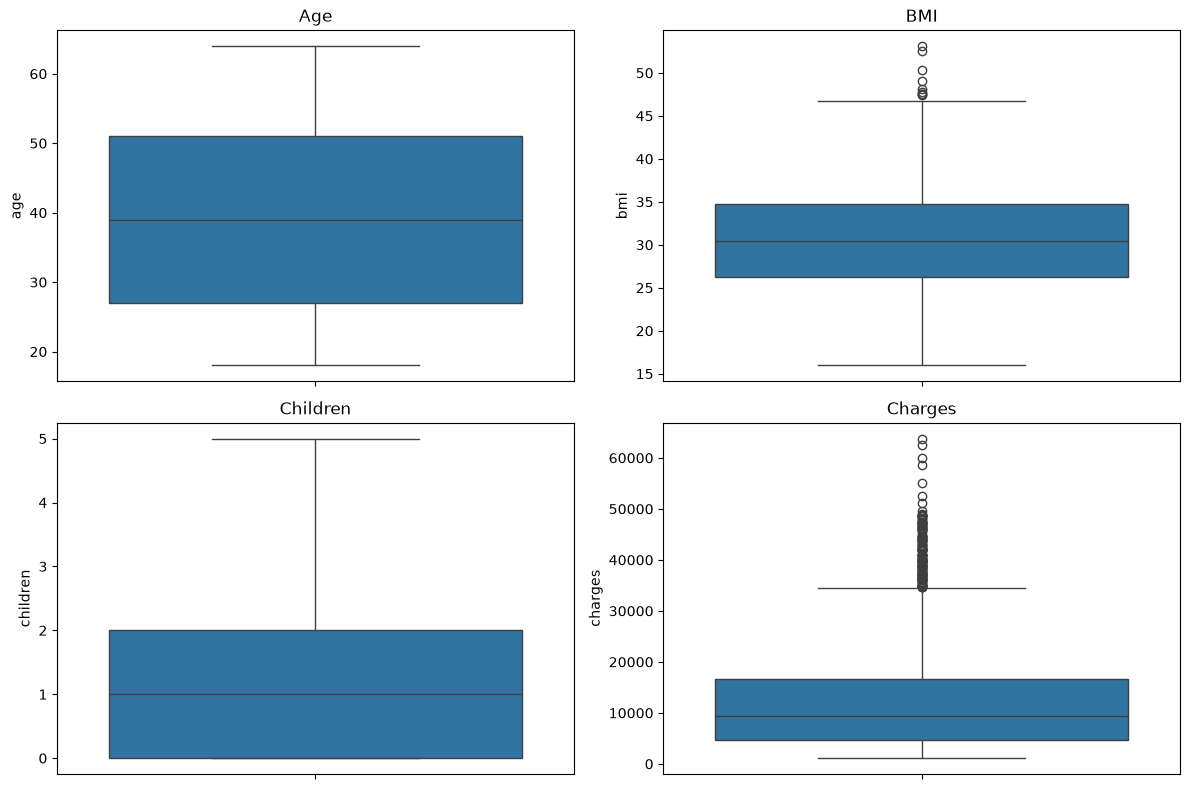

In [7]:
# plot numeric values
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot boxplot for 'age'
sns.boxplot(ax=axes[0, 0], data=insurance, y='age')
axes[0, 0].set_title('Age')

# Plot boxplot for 'bmi'
sns.boxplot(ax=axes[0, 1], data=insurance, y='bmi')
axes[0, 1].set_title('BMI')

# Plot boxplot for 'children'
sns.boxplot(ax=axes[1, 0], data=insurance, y='children')
axes[1, 0].set_title('Children')

# Plot boxplot for 'charges'
sns.boxplot(ax=axes[1, 1], data=insurance, y='charges')
axes[1, 1].set_title('Charges')

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [8]:
# distribution of category columns
insurance['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [9]:
insurance['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [10]:
insurance['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [11]:
# distribution of numeric data

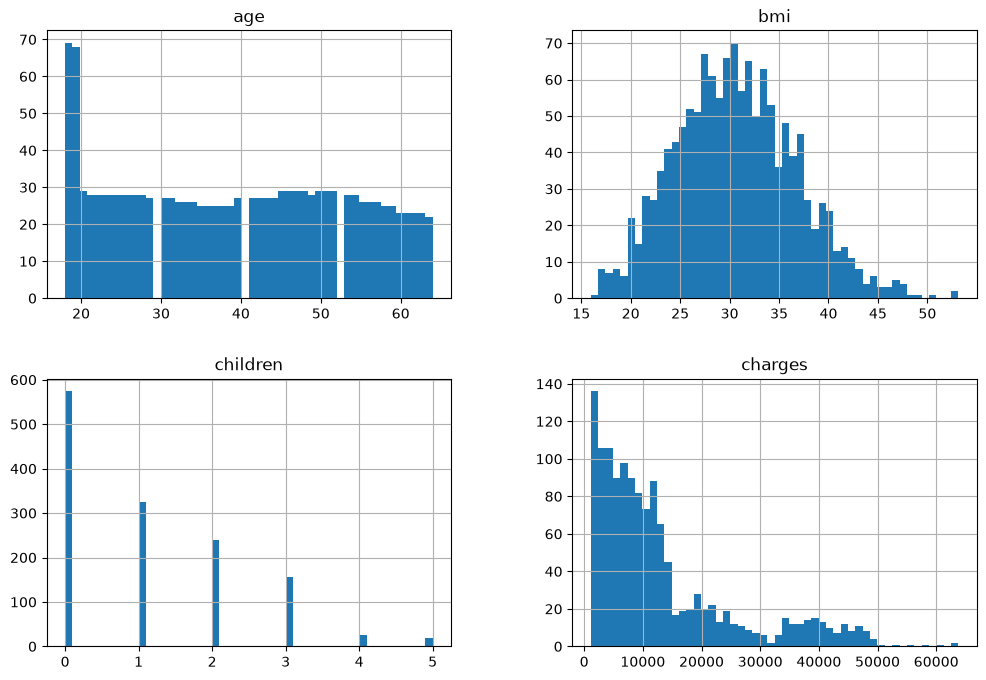

In [12]:
insurance.hist(bins=50, figsize=(12, 8))
plt.show()

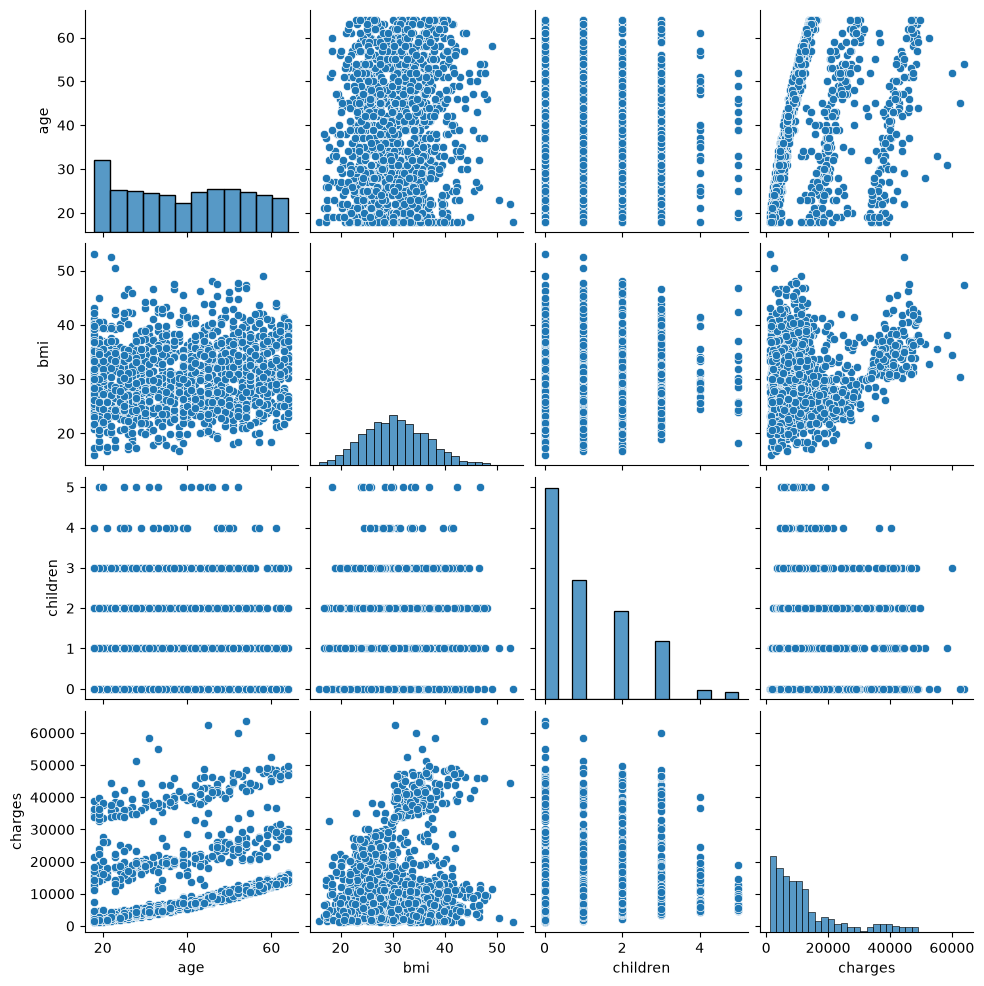

In [14]:
sns.pairplot(insurance[['age', 'bmi', 'children', 'charges']])
plt.show()

In [15]:
# correlation table 
correlation_table = insurance.corr(numeric_only=True).round(2)
display(correlation_table)

,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


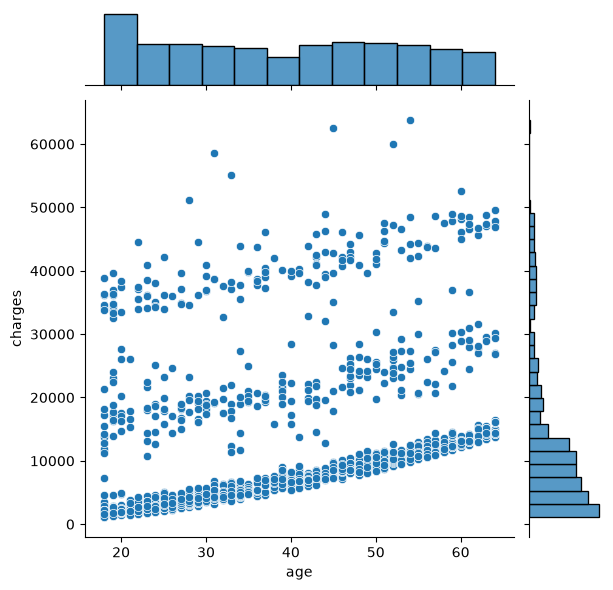

In [16]:
sns.jointplot(data=insurance, x="age", y="charges")

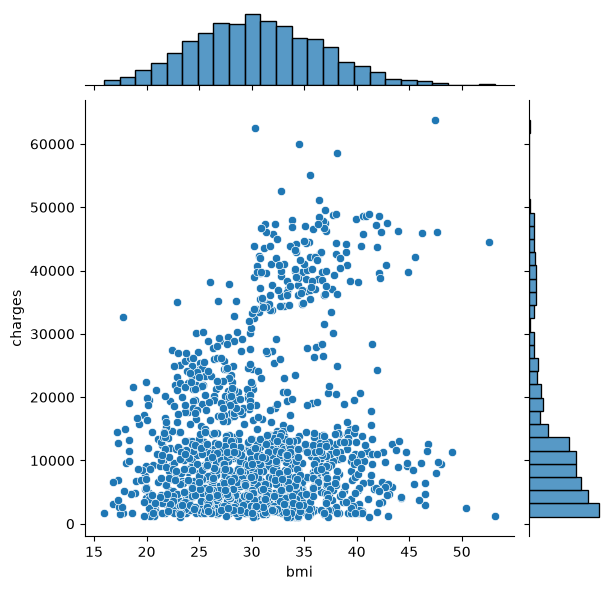

In [17]:
sns.jointplot(data=insurance, x="bmi", y="charges")

In [145]:
#check VIF
# Apply the pipeline's fitted preprocessing steps
train_transformed = lin_reg[:-1].transform(insurance_training)

# Convert sparse output to a dense array if needed
if hasattr(train_transformed, "toarray"):
    train_transformed = train_transformed.toarray()

feature_names = lin_reg[:-1].get_feature_names_out()

# Add an intercept for the auxiliary regressions used to calculate VIF
train_vif = pd.DataFrame(train_transformed, columns=feature_names)
train_vif = sm.add_constant(train_vif, has_constant="add")

# Calculate VIF for each feature; exclude the intercept
vif_table = pd.DataFrame({
    "Feature": feature_names,
    "VIF": [
        variance_inflation_factor(train_vif.to_numpy(), i)
        for i in range(1, train_vif.shape[1])
    ]
})

display(vif_table.sort_values("VIF", ascending=False).round(2))

,Feature,VIF
4,reg__region_southeast,1.66
3,reg__region_northwest,1.53
5,reg__region_southwest,1.52
1,num__bmi,1.13
7,bin__smoker_yes,1.02
0,num__age,1.02
6,bin__sex_male,1.01
2,num__children,1.01


# Data Splitting

In [18]:
strat_train_set, strat_test_set = train_test_split(
    insurance, test_size=0.3, stratify=pd.cut(insurance['bmi'],bins=4), random_state=42)

insurance_training  = strat_train_set.drop("charges", axis=1)
charges_training = strat_train_set["charges"].copy()

# Data preparation

In [20]:
# encode categorical data
region_encoder = OneHotEncoder(drop="first")
binary_encoder = OneHotEncoder(drop='if_binary')
                               
encoded_region = region_encoder.fit_transform(insurance[["region"]])
encoded_df = pd.DataFrame(
    encoded_region.toarray(),
    columns=region_encoder.get_feature_names_out(["region"]),
    index=insurance.index
)

In [21]:
encoded_df

,region_northwest,region_southeast,region_southwest
0,0.0,0.0,1.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
1333,1.0,0.0,0.0
1334,0.0,0.0,0.0
1335,0.0,1.0,0.0
1336,0.0,0.0,1.0


In [22]:
#Standardize numeric values
ins_num = insurance_training[['age', 'bmi', 'children']]
std_scaler = StandardScaler()
ins_num_std_scaled = std_scaler.fit_transform(ins_num)
ins_num_std_scaled

array([[-1.02390632,  1.89480074, -0.05615395],
       [ 1.05251603,  0.85639657,  1.61242051],
       [-0.0930963 , -1.83046397,  0.77813328],
       ...,
       [ 1.48212066, -1.08064242, -0.89044118],
       [-1.31030941,  0.80953272, -0.89044118],
       [-1.31030941, -0.69175472, -0.05615395]], shape=(936, 3))

# Create a transformation pipeline

In [23]:
num_pipeline = Pipeline([
    ("standardize", StandardScaler()),
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, ['age', 'bmi', 'children']),
    ("reg", region_encoder, ['region']),
    ("bin", binary_encoder, ['sex','smoker']),
])

In [24]:
insurance_train_scaled = preprocessing.fit_transform(insurance_training)
print(preprocessing.get_feature_names_out())
print(insurance_train_scaled)

['num__age' 'num__bmi' 'num__children' 'reg__region_northwest'
 'reg__region_southeast' 'reg__region_southwest' 'bin__sex_male'
 'bin__smoker_yes']
[[-1.02390632  1.89480074 -0.05615395 ...  0.          0.
   0.        ]
 [ 1.05251603  0.85639657  1.61242051 ...  0.          0.
   0.        ]
 [-0.0930963  -1.83046397  0.77813328 ...  0.          0.
   0.        ]
 ...
 [ 1.48212066 -1.08064242 -0.89044118 ...  0.          0.
   0.        ]
 [-1.31030941  0.80953272 -0.89044118 ...  0.          1.
   0.        ]
 [-1.31030941 -0.69175472 -0.05615395 ...  1.          0.
   0.        ]]


# Train and Evaluate 

In [25]:
lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(insurance_training, charges_training)

ins_predictions = lin_reg.predict(insurance_training)

In [26]:
print("Coefficients:\n", lin_reg[-1].coef_)
print("Intercept:", lin_reg[-1].intercept_)

Coefficients:
 [ 3745.80443913  2254.06506904   750.52726519  -708.29001367
 -1064.26041765 -1020.36736602  -229.68855182 23760.60499726]
Intercept: 9279.694481006682


In [27]:
# show P-values and model summary 
# Fit the linear regression model
X2 = sm.add_constant(preprocessing.fit_transform(insurance_training, charges_training))
model = sm.OLS(charges_training, X2).fit()

# Display the p-values and coefficients
model.use_t = True
print("P-values:")
feature_names = lin_reg[:-1].get_feature_names_out()
names = ["const"] + list(feature_names)
pvals = np.asarray(model.pvalues).ravel()

p_values = pd.DataFrame(list(zip(names, pvals)),columns=["Feature", "P-value"])

p_values.index = [f"x{i}" for i in range(0, len(p_values))]
display(p_values)

print(model.summary())

P-values:


,Feature,P-value
x0,const,9.900799e-73
x1,num__age,5.849637e-65
x2,num__bmi,9.718772e-25
x3,num__children,2.067929e-04
x4,reg__region_northwest,2.124673e-01
x5,reg__region_southeast,7.056207e-02
x6,reg__region_southwest,7.993209e-02
x7,bin__sex_male,5.700641e-01
x8,bin__smoker_yes,1.003370e-253


                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     358.5
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          1.43e-277
Time:                        12:24:17   Log-Likelihood:                -9487.9
No. Observations:                 936   AIC:                         1.899e+04
Df Residuals:                     927   BIC:                         1.904e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9279.6945    469.899     19.748      0.0

In [28]:
mae = mean_absolute_error(charges_training, ins_predictions)
rmse = mean_squared_error(charges_training, ins_predictions)
r2 = r2_score(charges_training, ins_predictions)

def root_mean_squared_log_error(actual, predicted):
    actual = np.maximum(np.asarray(actual, dtype=float), 0)
    predicted = np.maximum(np.asarray(predicted, dtype=float), 0)
    return float(np.sqrt(np.mean((np.log1p(predicted) - np.log1p(actual)) ** 2)))

rmsle = root_mean_squared_log_error(charges_training, ins_predictions)

print(f"MAE: {mae}, RMSE: {rmse}, R²: {r2}, RMSLE: {rmsle}")

MAE: 4322.582210509713, RMSE: 37337219.58536236, R²: 0.7557118637981783, RMSLE: 1.2938220992874476


# model diagnosis

,Fold,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2
0,1,4205.864,4662.010,5939.190,6766.315,0.766,0.714
1,2,4329.344,4043.537,6219.970,5664.873,0.751,0.777
2,3,4305.451,4531.945,6066.450,6348.644,0.752,0.762
3,4,4253.756,4605.735,6018.028,6493.078,0.759,0.742
4,5,4489.660,4021.150,6263.903,5526.336,0.754,0.756


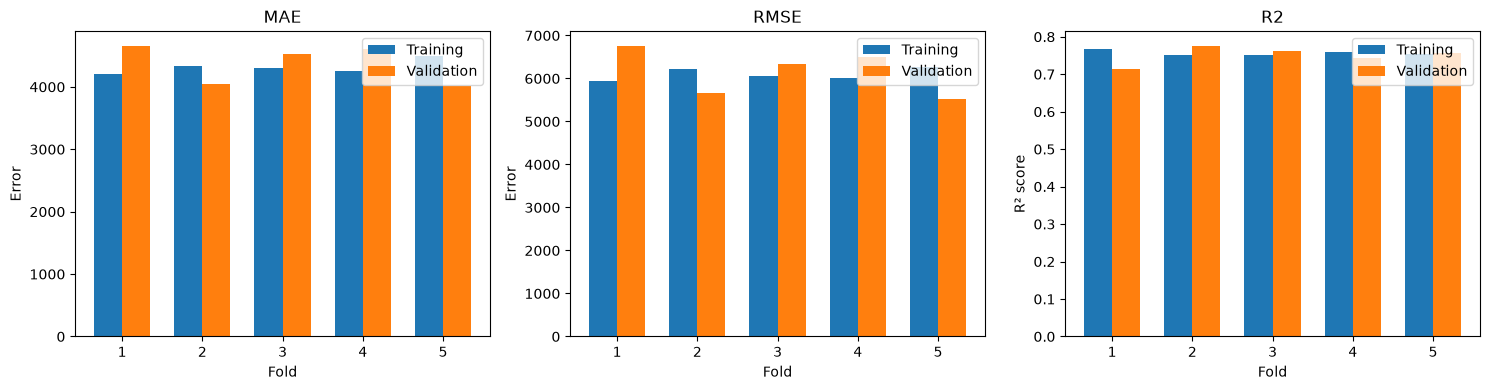

,Validation MAE,Validation RMSE,Validation R2
mean,4372.876,6159.849,0.750
std,314.364,538.708,0.024


In [29]:
# Compare training and validation performance

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# cross_validate clones and refits the full pipeline in each fold
scores = cross_validate(
    lin_reg,
    insurance_training,
    charges_training,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True
)

# MAE and RMSE are returned as negative scores, so convert them to positive values
fold_metrics = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Train MAE": -scores["train_MAE"],
    "Validation MAE": -scores["test_MAE"],
    "Train RMSE": -scores["train_RMSE"],
    "Validation RMSE": -scores["test_RMSE"],
    "Train R2": scores["train_R2"],
    "Validation R2": scores["test_R2"]
})

display(fold_metrics.round(3))

# Plot each metric across the five folds
folds = fold_metrics["Fold"]
x = np.arange(len(folds))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    ax.bar(x - width / 2, fold_metrics[f"Train {metric}"],
           width, label="Training")
    ax.bar(x + width / 2, fold_metrics[f"Validation {metric}"],
           width, label="Validation")

    ax.set_title(metric)
    ax.set_xlabel("Fold")
    ax.set_xticks(x, folds)
    ax.legend()

axes[0].set_ylabel("Error")
axes[1].set_ylabel("Error")
axes[2].set_ylabel("R² score")

plt.tight_layout()
plt.show()

# Mean and standard deviation across the validation folds
summary = fold_metrics[
    ["Validation MAE", "Validation RMSE", "Validation R2"]
].agg(["mean", "std"])

display(summary.round(3))

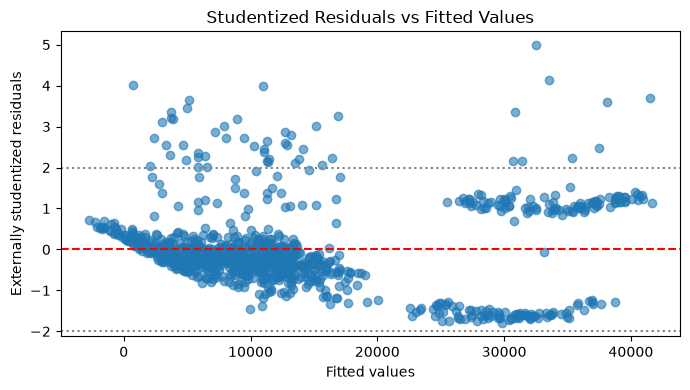

In [30]:
influence = model.get_influence()
studentized_residuals = influence.resid_studentized_external
fitted_values = model.fittedvalues

plt.figure(figsize=(7, 4))
plt.scatter(fitted_values, studentized_residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.axhline(2, color="grey", linestyle=":")
plt.axhline(-2, color="grey", linestyle=":")
plt.xlabel("Fitted values")
plt.ylabel("Externally studentized residuals")
plt.title("Studentized Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

# Evaluate the model on test data

In [31]:
# validate the model on the test set
ins_test = strat_test_set.drop("charges", axis=1)
charges_test = strat_test_set["charges"].copy()
ins_predictions_test = lin_reg.predict(ins_test)
# Compute RMSE
rmse_test = mean_squared_error(charges_test , ins_predictions_test)
rmsle_test = root_mean_squared_log_error(charges_test , ins_predictions_test)
print(f"RMSE: {rmse_test}, RMSLE: {rmsle_test}")

RMSE: 35012422.90569907, RMSLE: 1.2592849936937827
